# A more transparent EsT X gate: seed selection

This notebook records a search for an error-semitransparent (EsT) X gate that is more transparent than the one
used in `FWM_tails.ipynb` §3 (`pulses/dgrape/u_X_est_closed.npy`). The training cost is
`est_optimization.ipynb` §7's: the EsT cost plus an error-space fidelity term in the first stage. Many random
starts (seeds) are trained, and a rule fixed before training picks the best ones.

**Glossary.**
- **EsT gate**: a gate trained so that a photon lost during the gate leaves a clean, correctable error.
- **Code words** $|0_L\rangle=(|1\rangle+|5\rangle)/\sqrt2$ and $|1_L\rangle=|3\rangle$: the odd kitten code.
- **Error words**: the normalized states $a|0_L\rangle$ and $a|1_L\rangle$, which are $(|0\rangle+\sqrt5|4\rangle)/\sqrt6$ and $|2\rangle$.
- **Seed**: the random number that sets the smooth starting pulse. The same cost from a different seed can end
  in a different pulse.
- The three transparency (ET) metrics, each 0 for a perfectly transparent gate, all from Eqs. 6-8 of Roy,
  Wetherbee & Fatemi (arXiv:2603.15356):
  - $\Delta_{\rm QEC}(t)$: how far the evolved code words are from the Knill-Laflamme conditions for the errors $\{I, a\}$.
  - $L(t)$: how much of the evolved error state has left the error space at time $t$.
  - $\eta(t)$: the distance between the Bloch vectors of the code state and of the (projected) error state,
    averaged over the six cardinal states.

§7 searches for an EsT H gate. At X's 1.1 μs no H seed passes the rule; at 2 μs, which the Shirol chip's smaller dispersive shift calls for, six of 50 seeds do. With the stricter peak ΔQEC bar of 0.4 that the user then set, two remain: seed 17, the H pick, and seed 27.

All data come from `DGRAPE/est_gate_seeds.py`. This notebook only reads its tables and does no training.

## Setup

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

os.chdir(os.path.abspath(""))     # run from the repository root
from DGRAPE import est_gate_seeds as S

runs = pd.read_csv(S.RUNS_CSV)
pick = pd.read_csv(S.PICK_CSV)
tr = np.load(S.TRACES_NPZ)
fin = runs[runs.stage == "final"].set_index("name")
st1 = runs[runs.stage == "stage1"].set_index("name")
trained = fin[fin.kind == "run"]
print(f"{len(trained)} trained seeds, {len(fin) - len(trained)} reference gates")

50 trained seeds, 3 reference gates


# 1. The simulation

**System.** It is the same closed system as the EsT gate of `FWM_tails.ipynb` §3, with Shirol's chip
(`AQEC/device.py`), the storage cavity and a three-level transmon, and the readout dropped (it is inert during
a gate). The higher-order terms (Kerr, $\chi'$) are on. The gate is X on the odd kitten code, which starts and
ends with the transmon in $|g\rangle$. The gate lasts 1.1 μs with a 2 ns step (550 steps). The drives are
limited as for d2: bands ±27 MHz (cavity) and ±33 MHz (transmon), a 48 ns ramp, a box $|x|\le 25$ on the
pre-image and a cap $|\varepsilon|\le 25$ rad/μs per drive. Training uses 20 storage levels, and every score
here uses 24 levels.

**Cost** (`EST/grape_eigh.cost_and_grad`, exact gradient):
- $C_1$: the gate error on the six code cardinals.
- $C_2$: the transparency error along the gate.
- $C_3$: the variance of the code state's speed, which stops "parking".
- $C_4$: the drive cap.
- $C_{\rm err}$: $C_1$'s form on the six error cardinals at $t=T$, against the ideal X in the error basis.

Training has two L-BFGS-B stages of 2000 iterations each, as in `est_optimization.ipynb` §7:

| stage | $(w_1, w_2, w_3, w_4, w_{\rm err})$ |
|---|---|
| 1 | (1, 0.7, 7, 1, 0.3) |
| 2 | (1, 0.1, 0, 1, 0) |

**Seeds.** Each run starts from d2's smooth random pulse (`core.optimizer.make_smooth_warm_start`) at its
seed. Wave 1 is seeds 0-24. The rule said wave 2 (seeds 25-49) runs only if wave 1 gives fewer than 3
candidates. Wave 1 gave 3, but wave 2 was run anyway at the user's request, so all 50 seeds are trained and ranked
together under the same rule. Each run uses one BLAS thread on the Windows PC.

**Rule (fixed 2026-10-29, before training).** A trained gate is a *candidate* if all of these hold:
- $F_1 \ge 0.99$, and it is not parked (a parked gate barely drives).
- Peaks: $\max_t \Delta_{\rm QEC} \le 0.5$, $\max_t L \le 0.5$ and $\max_t \eta \le 0.5$.
- Tails (the mean over $t \ge 0.9\,T$): $\Delta_{\rm QEC} \le 0.1$, $L \le 0.2$ and $\eta \le 0.2$.
- $|F_1(n_c{=}28) - F_1(n_c{=}24)| < 10^{-4}$, so the gate does not lean on the truncation.

Candidates are ranked by **score** = (mean $\Delta_{\rm QEC}$ + mean $L$ + mean $\eta$)/3, lowest first. The
*current gate* is `X_est_closed` (plain EsT cost, seed 42). Two other samples of that training are scored as
references: seed 43 and seed 44 (which parked).

# 2. All runs

In [2]:
cols = {"seed": "seed", "tier": "tier", "F1": "F1", "score": "score", "dqec_mean": "mean ΔQEC",
        "L_mean": "mean L", "eta_mean": "mean η", "dqec_peak": "peak ΔQEC", "L_peak": "peak L",
        "eta_peak": "peak η", "dqec_tail": "tail ΔQEC", "L_tail": "tail L", "eta_tail": "tail η",
        "L_T": "L(T)", "trunc_spread": "|F1(28)-F1(24)|", "max_active_fock": "max Fock"}
tab = fin.reset_index().sort_values(["kind", "seed"], ascending=[False, True])
tab = tab.assign(seed=[f"{s}" if k == "run" else f"{s} (ref: {n})" for s, k, n in zip(tab.seed, tab.kind, tab.name)])
fmt = {c: "{:.3f}" for c in cols.values() if c not in ("seed", "tier")}
fmt.update({"F1": "{:.5f}", "|F1(28)-F1(24)|": "{:.1e}", "max Fock": "{:.0f}"})
display(tab[list(cols)].rename(columns=cols).style.format(fmt).hide(axis="index")
        .set_caption("Table 1. Every trained seed and the reference gates, final pulses, closed system at n_c 24"))
print("tiers of the trained seeds:", trained.tier.value_counts().to_dict())
print("after stage 1 (trained seeds):", st1[st1.kind == "run"].tier.value_counts().to_dict())

seed,tier,F1,score,mean ΔQEC,mean L,mean η,peak ΔQEC,peak L,peak η,tail ΔQEC,tail L,tail η,L(T),|F1(28)-F1(24)|,max Fock
0,open,0.99868,0.133,0.116,0.201,0.082,0.463,0.491,0.203,0.004,0.211,0.054,0.133,1.8e-07,14
1,parked,0.33118,0.003,0.000,0.000,0.010,0.000,0.001,0.020,0.000,0.001,0.019,0.001,2.2e-16,5
2,parked,0.33118,0.003,0.000,0.000,0.010,0.000,0.001,0.020,0.000,0.001,0.019,0.001,8.7e-15,5
3,open,0.99816,0.157,0.124,0.219,0.126,0.538,0.556,0.297,0.013,0.153,0.165,0.125,3.5e-08,15
4,parked,0.33118,0.003,0.000,0.000,0.010,0.000,0.001,0.020,0.000,0.001,0.019,0.001,1.4e-14,5
5,open,0.99337,0.258,0.261,0.309,0.203,0.914,0.608,0.518,0.023,0.293,0.096,0.190,1.4e-04,19
6,parked,0.33118,0.003,0.000,0.000,0.010,0.000,0.001,0.020,0.000,0.001,0.019,0.001,7.1e-15,5
7,closed,0.99902,0.142,0.117,0.204,0.105,0.445,0.418,0.229,0.002,0.170,0.129,0.127,1.2e-08,13
8,open,0.99862,0.154,0.141,0.210,0.111,0.649,0.428,0.226,0.004,0.180,0.137,0.128,6.3e-08,14
9,wall,0.10474,1.752,4.154,0.600,0.503,13.456,0.833,1.501,2.948,0.735,0.543,0.733,3.1e-02,23


tiers of the trained seeds: {'open': 24, 'parked': 22, 'closed': 3, 'wall': 1}
after stage 1 (trained seeds): {'parked': 49, 'open': 1}


*Table 1.* One row per final pulse. "tail" is the mean over the last 10% of the gate. A **parked**
gate barely drives, so its transparency numbers are near 0 and mean nothing. An **open** gate has
$F_1 < 0.999$, and a **closed** gate has $F_1 \ge 0.999$.
*Symbols:* $F_1$ = mean fidelity of the six code cardinals at $T$. The score is the mean of the three time
means. $L(T)$ = leakage at the last step. Max Fock = the highest storage level above 1% population at any time.

# 3. Selection

In [3]:
checks = ["F1_ok", "dqec_peak_ok", "L_peak_ok", "eta_peak_ok", "dqec_tail_ok", "L_tail_ok", "eta_tail_ok",
          "trunc_ok"]
p = pick.copy()
p["name"] = [f"seed {s}" if k == "run" else f"ref {n}" for s, k, n in zip(p.seed, p.kind, p.name)]
show = p[["name", "rank", "score", "F1", "beats_current"] + checks]
show = show.assign(**{c: show[c].map({True: "✓", False: "✗"}) for c in checks + ["beats_current"]})
display(show.style.format({"score": "{:.3f}", "F1": "{:.5f}", "rank": "{:.0f}"}, na_rep="")
        .hide(axis="index").set_caption("Table 2. The rule, check by check"))
fails = (~pick[pick.kind == "run"][checks].astype(bool)).sum()
print("trained seeds failing each check:", fails.to_dict())
cur = fin.loc[S.CURRENT]
cand = pick[pick["rank"].notna()].sort_values("rank")
print(f"{len(cand)} candidates; current gate score {cur.score:.3f}")

name,rank,score,F1,beats_current,F1_ok,dqec_peak_ok,L_peak_ok,eta_peak_ok,dqec_tail_ok,L_tail_ok,eta_tail_ok,trunc_ok
seed 24,1,0.110,0.99871,✓,✓,✓,✓,✓,✓,✓,✓,✓
seed 45,2,0.127,0.99819,✓,✓,✓,✓,✓,✓,✓,✓,✓
seed 38,3,0.130,0.99888,✓,✓,✓,✓,✓,✓,✓,✓,✓
seed 16,4,0.141,0.99844,✓,✓,✓,✓,✓,✓,✓,✓,✓
seed 7,5,0.142,0.99902,✓,✓,✓,✓,✓,✓,✓,✓,✓
ref X_est_closed_s43,,0.135,0.99848,✓,✓,✓,✓,✓,✓,✓,✓,✓
seed 31,,0.003,0.33118,✗,✗,✓,✓,✓,✓,✓,✓,✓
seed 47,,0.003,0.33118,✗,✗,✓,✓,✓,✓,✓,✓,✓
seed 49,,0.003,0.33118,✗,✗,✓,✓,✓,✓,✓,✓,✓
seed 30,,0.003,0.33118,✗,✗,✓,✓,✓,✓,✓,✓,✓


trained seeds failing each check: {'F1_ok': 24, 'dqec_peak_ok': 12, 'L_peak_ok': 16, 'eta_peak_ok': 3, 'dqec_tail_ok': 1, 'L_tail_ok': 14, 'eta_tail_ok': 3, 'trunc_ok': 3}
5 candidates; current gate score 0.203


*Table 2.* ✓ means the check passes. Rank is given only to trained seeds that pass every check. "beats
current" means the score is lower than `X_est_closed`'s.
*Symbols:* the peak checks are $\max_t$ over the whole gate. The tail checks are means over $t\ge0.9\,T$.
trunc_ok means $|F_1(28)-F_1(24)|<10^{-4}$.

In [4]:
TOP = list(cand.name[:3])
rows = []
for n in TOP + [S.CURRENT]:
    r = fin.loc[n]
    rows.append({"gate": f"seed {r.seed}" if n != S.CURRENT else "current (seed 42)", "F1": r.F1,
                 "score": r.score, "mean ΔQEC": r.dqec_mean, "mean L": r.L_mean, "mean η": r.eta_mean,
                 "peak ΔQEC": r.dqec_peak, "peak L": r.L_peak, "peak η": r.eta_peak, "tail ΔQEC": r.dqec_tail,
                 "tail L": r.L_tail, "tail η": r.eta_tail, "L(T)": r.L_T, "max Fock": r.max_active_fock,
                 "F1 after stage 1": st1.loc[n].F1 if n in st1.index else np.nan})
top = pd.DataFrame(rows).set_index("gate")
display(top.T.style.format("{:.4f}").set_caption("Table 3. The top candidates against the current gate"))

gate,seed 24,seed 45,seed 38,current (seed 42)
F1,0.9987,0.9982,0.9989,0.9979
score,0.1104,0.1267,0.1296,0.2025
mean ΔQEC,0.0536,0.0796,0.0879,0.2013
mean L,0.1983,0.2120,0.1996,0.2684
mean η,0.0792,0.0885,0.1014,0.1379
peak ΔQEC,0.2324,0.2923,0.3380,0.6091
peak L,0.4908,0.4904,0.4767,0.5244
peak η,0.2427,0.2286,0.1887,0.2950
tail ΔQEC,0.0035,0.0145,0.0030,0.0180
tail L,0.1714,0.1914,0.1532,0.2722


*Table 3.* The three best-ranked candidates next to the current EsT gate.
*Symbols:* as in Table 1.

# 4. The three metrics over the gate

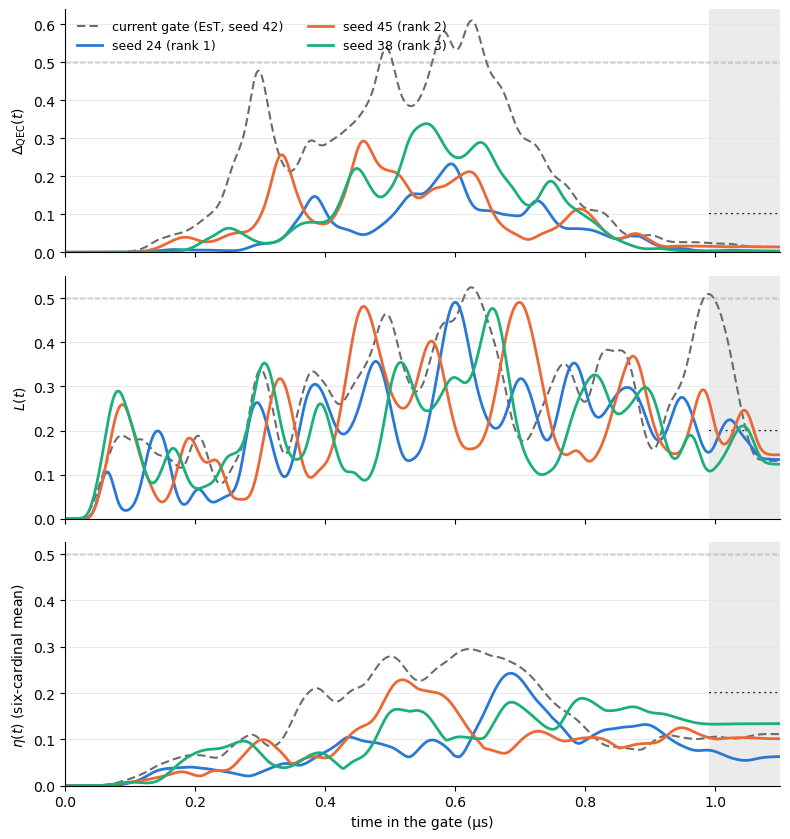

In [5]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]           # categorical slots 1-3; the current gate in gray
CUR_COLOR = "#6b6b6b"
panels = [("dqec", r"$\Delta_{\rm QEC}(t)$", S.PEAK_MAX["dqec"], S.TAIL_MAX["dqec"]),
          ("L", r"$L(t)$", S.PEAK_MAX["L"], S.TAIL_MAX["L"]),
          ("eta", r"$\eta(t)$ (six-cardinal mean)", S.PEAK_MAX["eta"], S.TAIL_MAX["eta"])]
fig, axes = plt.subplots(3, 1, figsize=(8, 8.5), sharex=True)
T_g = tr[f"{S.CURRENT}/final/t"][-1]
for ax, (key, label, peak, tail) in zip(axes, panels):
    ax.axvspan(S.TAIL_FRAC * T_g, T_g, color="0.92", zorder=0)
    ax.axhline(peak, color="0.4", lw=1, ls="--", zorder=1)
    ax.hlines(tail, S.TAIL_FRAC * T_g, T_g, color="0.15", lw=1.5, ls=":", zorder=1)
    t = tr[f"{S.CURRENT}/final/t"]
    ax.plot(t, tr[f"{S.CURRENT}/final/{key}"], color=CUR_COLOR, lw=1.5, ls=(0, (4, 2)),
            label="current gate (EsT, seed 42)")
    for c, n in zip(COLORS, TOP):
        ax.plot(tr[f"{n}/final/t"], tr[f"{n}/final/{key}"], color=c, lw=2,
                label=f"seed {fin.loc[n].seed} (rank {int(cand.set_index('name').loc[n, 'rank'])})")
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
axes[-1].set_xlabel("time in the gate (μs)")
axes[-1].set_xlim(0, T_g)
fig.tight_layout()
os.makedirs("figures/est", exist_ok=True)
fig.savefig("figures/est/fig_est_gate_seeds_top_X.png", dpi=150)
plt.show()

*Figure 1.* The three transparency metrics over the gate for the top three candidates (solid) and the current
EsT gate (gray, dashed). The gray band is the tail, $t \ge 0.9\,T$. The dashed line is the peak bar (0.5), and
the dotted line in the band is the tail bar, which applies to the band's mean, not to every point.
*Symbols:* $\Delta_{\rm QEC}$ = distance from the Knill-Laflamme conditions (Eq. 6, unnormalized); $L$ =
leakage of the error state out of the instantaneous error space (Eq. 7); $\eta$ = Bloch-vector distance
between the code state and the projected error state (Eq. 8, range 0-2), averaged over the six cardinals;
$T$ = 1.1 μs.

# 5. The top candidates in the open system

In [6]:
if os.path.exists(S.OPEN_CSV):
    op = pd.read_csv(S.OPEN_CSV)
    op["gate"] = [f"seed {fin.loc[n].seed}" if n != S.CURRENT else "current (seed 42)" for n in op.name]
    show = op.set_index("gate")[["F_pro_decay", "F_pro_all", "F_repaired", "repair_gain", "losses_per_gate",
                                 "f_midgate_loss_repaired"]]
    display(show.style.format({"F_pro_decay": "{:.5f}", "F_pro_all": "{:.5f}", "F_repaired": "{:.5f}",
                               "repair_gain": "{:+.2%}", "losses_per_gate": "{:.4f}",
                               "f_midgate_loss_repaired": "{:.3f}"})
            .set_caption("Table 4. Open-system scores (n_c 24), as in FWM_tails.ipynb Table 3"))
else:
    print("run: python DGRAPE/est_gate_seeds.py open_score --top 3")

,F_pro_decay,F_pro_all,F_repaired,repair_gain,losses_per_gate,f_midgate_loss_repaired
gate,,,,,,
seed 24,0.96706,0.95733,0.98699,+1.99%,0.0268,0.851
seed 45,0.96674,0.95668,0.98622,+1.95%,0.0265,0.839
seed 38,0.96764,0.95757,0.98721,+1.96%,0.0266,0.851
current (seed 42),0.96803,0.95594,0.98654,+1.85%,0.0268,0.861


*Table 4.* These numbers are reported only and play no part in the selection. F_pro_decay is the process
fidelity of the gate alone with the decay channels. F_pro_all adds dephasing and heating. F_repaired is
F_pro after an ideal repair at the end of the gate. repair_gain = F_repaired − F_pro_decay.
f_midgate_loss_repaired is the conditional fidelity of a photon lost during the gate after that repair,
averaged over the loss time.
*Symbols:* F_pro = process fidelity against the ideal X. The ideal repair maps every $|n\rangle \to |n+1\rangle$
pair back with the best phases (`fwm_tail.ideal_repair_fidelity`).

# 6. Conclusions

**The pick stays seed 24** (`pulses/dgrape/u_X_est_err_closed_s24.npy`). Both waves were run, 50 seeds in all.
Wave 1 alone met the stop rule (3 candidates). Wave 2 adds two more candidates, seeds 45 and 38, and neither beats
seed 24.

- **How the 50 starts ended.**

  | | wave 1 (seeds 0-24) | wave 2 (seeds 25-49) | all |
  |---|---|---|---|
  | parked | 12 | 10 | 22 |
  | trained against the wall | 1 (seed 9) | 0 | 1 |
  | made a gate | 12 | 15 | 27 |
  | candidates | 3 | 2 | 5 |

  - **Parked** runs have zero drive and F1 = 1/3 after stage 1, and they stay there through stage 2. C_err at 0.3
    parks 44% of the starts. Plain EsT parks 1 start in 3 on this chip (seed 44).
  - **Seed 9** reads F1 0.990 at the training truncation (20 levels) but 0.10 at 24 levels, and it reaches Fock 23.
    It is labelled "wall", not parked.
  - **The 27 gates** have F1 between 0.9880 and 0.9992. Only seed 35 (0.9880) is under the 0.99 bar. Three close
    by EST's stricter bar (F1 ≥ 0.999): seeds 7, 40 (0.9992, the best F1) and 48.
- **Five candidates pass every bar.**

  | rank | seed | wave | score | mean ΔQEC / L / η | peak ΔQEC / L / η | tail ΔQEC / L / η | F1 |
  |---|---|---|---|---|---|---|---|
  | 1 | 24 | 1 | 0.110 | 0.054 / 0.198 / 0.079 | 0.23 / 0.49 / 0.24 | 0.004 / 0.17 / 0.06 | 0.9987 |
  | 2 | 45 | 2 | 0.127 | 0.080 / 0.212 / 0.089 | 0.29 / 0.49 / 0.23 | 0.015 / 0.19 / 0.10 | 0.9982 |
  | 3 | 38 | 2 | 0.130 | 0.088 / 0.200 / 0.101 | 0.34 / 0.48 / 0.19 | 0.003 / 0.15 / 0.13 | 0.9989 |
  | 4 | 16 | 1 | 0.141 | 0.103 / 0.201 / 0.120 | 0.43 / 0.45 / 0.25 | 0.007 / 0.17 / 0.15 | 0.9984 |
  | 5 | 7 | 1 | 0.142 | 0.117 / 0.204 / 0.105 | 0.45 / 0.42 / 0.23 | 0.002 / 0.17 / 0.13 | 0.9990 |

  The current gate scores 0.203 and fails three bars: peak ΔQEC 0.61, peak L 0.52 and tail L 0.27. 24 of the 27
  gates score lower than it, so almost any driving start is more transparent on average. The bars, not the score,
  are what is hard to meet.
  - **Seed 24 against the current gate:** mean ΔQEC is 73% lower, mean L 26% lower and mean η 43% lower. Its ΔQEC
    peak halves (0.61 to 0.23). It uses fewer photon levels (Fock 13 against 15).
  - **Seed 24 against wave 2's best (seed 45):** seed 45's score is 15% higher (0.127 against 0.110), mostly from
    mean ΔQEC (0.080 against 0.054). Seed 24's lead (0.017) is larger than any gap between ranks 2-5 (at most 0.012).
- **The bars that bind are still on L.** Of the 27 gates, 15 fail the L peak and 13 fail the L tail. 11 fail the
  ΔQEC peak. No other bar fails more than twice, and no gate fails the ΔQEC tail.
  - Six gates fail only on tail L, at 0.202-0.225: seeds 0, 17, 18 (wave 1) and 34, 40, 42 (wave 2). Seed 40 is
    the best-F1 gate of the search and misses by tail L 0.2016.
  - Three fail only on peak L: seed 29 at 0.5006, seed 26 at 0.53 and seed 43 at 0.56.
  - Lowering L along the gate remains the hard part.
- **C_err is not what made the winners.** The plain EsT seed-43 sample also passes every bar, and its score of
  0.135 would place 4th, between seeds 38 and 16. Among C_err's 27 driving runs, 5 pass (19%). This is one seed batch,
  not a paired comparison, so the gain belongs to the seeds, not to the cost.
- **Open system (Table 4, now seeds 24, 45 and 38).** Higher transparency barely moves the gate's own process
  fidelity.
  - F_pro with decay is 0.9667-0.9676 against the current 0.9680.
  - With all channels it is 0.9567-0.9576 against 0.9559.
  - The ideal repair gains slightly more: +1.95-1.99% against +1.85%.
  - A photon lost mid-gate repairs to 0.84-0.85 against the current gate's 0.86.
  - Seeds 16 and 7, scored the same way after wave 1, gave the same picture (F_pro with decay up to 0.9680,
    repair gain +1.98-1.99%).

  So for the FWM tails, seed 24 offers about +0.14% of extra ideal-repair headroom, not a qualitatively more
  repairable gate. Wave 2 does not change that.

**Next.** Seed 24 can replace `X_est_closed` as the EsT gate in `FWM_tails.ipynb`. Pass
`--gate-pulse pulses/dgrape/u_X_est_err_closed_s24.npy --gate-n-c 24` to the tail trainer, at a 1 μs tail.
More seeds are unlikely to help: wave 2 found no better gate, and the rule's binding bars are on L, which the cost
does not target. A stronger transparency gain needs a cost on L(t) along the gate.
`est_optimization.ipynb`'s C_L term (`--w-leak`) is the existing one, but on the EST chip it cost F1.

# 7. The H gate

This section looks for an EsT **H** (Hadamard) gate on the same chip and code as the X gate of §1–§6. H sends the
cardinals $\pm Z \to \pm X$, $\pm X \to \pm Z$ and $\pm Y \to \mp Y$; a pulse that does nothing scores $F_1 = 1/3$,
as for X, so the "parked" tier is unchanged.

**Goal and rule (the user's, 2026-11-02).** A more transparent H gate, with
- good enough gate fidelity: $F_1 \ge 0.99$ (and not parked);
- low averages of the three ET metrics: candidates are ranked by the **mean score** of §1,
  (mean $\Delta_{\rm QEC}$ + mean $L$ + mean $\eta$)/3, lowest first;
- no large peaks: peak $\Delta_{\rm QEC} \le 0.4$, peak $L \le 0.5$, peak $\eta \le 0.5$. The ΔQEC bar
  was 0.5, as for X; the user lowered it to 0.4 after the first look at the results (2026-11-02);
- a transparent end of the gate: tail (mean over $t \ge 0.9\,T$) $\Delta_{\rm QEC} \le 0.1$, $L \le 0.2$,
  $\eta \le 0.2$;
- and $|F_1(28) - F_1(24)| < 10^{-4}$, as for X. Apart from the ΔQEC peak, these are the bars of §1.

**How we got here.** A first attempt at X's 1.1 μs found no H candidate in 50 seeds (§7.1, full record in
Appendix B). The Shirol chip's dispersive shift is 3.3 times smaller than the EST paper's, so its gates need more
time (§7.2). §7.3–§7.8 train the H gate at **2 μs**, 50 seeds in two waves of 25.

**Result.** At 2 μs six of 50 seeds pass the bars of §1 (7, 17 and 23 in the first wave, 27, 35 and 45 in the
second). With the ΔQEC peak at 0.4, **two pass: seed 17, the H pick, and seed 27**. The second wave added a
runner-up but did not change the pick. Seed 17's mean score (0.086) is lower than the X pick's (0.110).


In [7]:
# 1.1 us: the first attempt (§7.1, Appendix B)
PH = S.paths("H")
runsH = pd.read_csv(PH["runs_csv"])
pickH = pd.read_csv(PH["pick_csv"])
trH = np.load(PH["traces_npz"])
finH = runsH[runsH.stage == "final"].set_index("name")
st1H = runsH[runsH.stage == "stage1"].set_index("name")
gatesH = finH[finH.tier.isin(["open", "closed"])]            # the runs that made a gate
X_PICK = S.tag(24)                                           # §6's X pick, shown for scale only
T_g = tr[f"{X_PICK}/final/t"][-1]                            # 1.1 us
P2 = S.paths("H", "est_err2")                                # C_err kept in stage 2 (Appendix B.4)
runs2 = pd.read_csv(P2["runs_csv"])
pick2 = pd.read_csv(P2["pick_csv"])
tr2 = np.load(P2["traces_npz"])
fin2 = runs2[runs2.stage == "final"].set_index("seed")
seeds2 = sorted(fin2.index)
name1 = {s: S.tag(s, "H") for s in seeds2}
name2 = {s: S.tag(s, "H", "est_err2") for s in seeds2}
# 2 us: the search of §7.3-§7.8
PT = S.paths("H", duration=2.0)
runsT = pd.read_csv(PT["runs_csv"])
pickT = pd.read_csv(PT["pick_csv"])
trT = np.load(PT["traces_npz"])
finT = runsT[runsT.stage == "final"].set_index("name")
st1T = runsT[runsT.stage == "stage1"].set_index("name")
candT = pickT[pickT["rank"].notna()].sort_values("rank")
# the gates that fail only the lowered peak-dQEC bar (0.4) and pass §1's 0.5: the candidates at 0.5, for comparison
fail_dq_only = (pickT.n_fail == 1) & ~pickT.dqec_peak_ok.astype(bool)
AT05_T = list(pickT[fail_dq_only & (finT.loc[pickT.name, "dqec_peak"].values <= S.PEAK_MAX["dqec"])]
              .sort_values("score").name)
TOP_T = (list(candT.name) + AT05_T)[:3]                     # Table 9 / Figure 3: the top 3, filled from AT05_T


def lab_T(n):
    """Legend/row label of a 2 us H gate: its rank, or that it passes only at §1's 0.5 bar."""
    r = pickT.set_index("name").loc[n, "rank"]
    return f"seed {finT.loc[n].seed} " + (f"(rank {int(r)})" if r == r else "(passes at 0.5 only)")
for lab, f, s1 in (("H 1.1 us", finH, st1H), ("H 2 us", finT, st1T)):
    print(f"{lab}: {len(f)} trained seeds; final tiers {f.tier.value_counts().to_dict()}; "
          f"after stage 1 {s1.tier.value_counts().to_dict()}")


H 1.1 us: 50 trained seeds; final tiers {'parked': 28, 'open': 21, 'wall': 1}; after stage 1 {'parked': 41, 'open': 9}
H 2 us: 50 trained seeds; final tiers {'closed': 44, 'open': 5, 'wall': 1}; after stage 1 {'open': 35, 'parked': 15}


## 7.1 First attempt at 1.1 μs

The H search first mirrored X exactly: the same cost, 1.1 μs, 50 seeds, ranked by peak score (the user's choice
then, 2026-11-01). It found **no candidate**. A follow-up kept $C_{\rm err}$ on in stage 2 (variant `est_err2`,
the user's choice, 2026-11-02), and it found none either. Table 5 counts the outcomes, and Figure 2 shows where the
transparency is lost. Appendix B holds the full record.


In [8]:
def counts(f, p, label, seeds):
    r = f[f.kind == "run"]
    g = r[r.tier.isin(["open", "closed"])]
    return {"search": label, "seeds": seeds, "parked": int((r.tier == "parked").sum()),
            "wall": int((r.tier == "wall").sum()), "made a gate": len(g),
            "candidates": int(p[p.kind == "run"].candidate.sum()), "median F1 (gates)": g.F1.median(),
            "median score": g.score.median(), "median tail L": g.L_tail.median(),
            "median tail η": g.eta_tail.median()}

cnt = pd.DataFrame([counts(fin, pick, "X, 1.1 μs (§2-§6)", "0-49"),
                    counts(finH, pickH, "H, 1.1 μs", "0-49"),
                    counts(fin2, pick2, "H, 1.1 μs, C_err kept in stage 2", "the 21 gates"),
                    counts(finT, pickT, "H, 2 μs (§7.4-§7.8)", "0-49")]).set_index("search")
display(cnt.style.format({"median F1 (gates)": "{:.4f}", "median score": "{:.3f}", "median tail L": "{:.3f}",
                          "median tail η": "{:.3f}"})
        .set_caption("Table 5. How each search ended"))


,seeds,parked,wall,made a gate,candidates,median F1 (gates),median score,median tail L,median tail η
search,,,,,,,,,
"X, 1.1 μs (§2-§6)",0-49,22,1,27,5,0.9984,0.142,0.193,0.101
"H, 1.1 μs",0-49,28,1,21,0,0.9982,0.215,0.425,0.857
"H, 1.1 μs, C_err kept in stage 2",the 21 gates,0,0,21,0,0.9468,0.260,0.291,0.430
"H, 2 μs (§7.4-§7.8)",0-49,0,1,49,2,0.9996,0.109,0.284,0.370


*Table 5.* One row per search. "made a gate" counts the final pulses that are neither parked nor against the
truncation wall; the medians are over those gates. At 1.1 μs every H gate fails the L and η bars (median tail η
0.86 against X's 0.10). Keeping $C_{\rm err}$ in stage 2 lowers η but costs $F_1$ (all 21 below 0.99). At 2 μs no
start parks and 49 of 50 make a gate. Two pass the rule with the peak ΔQEC bar at 0.4 (six
pass at §1's 0.5).
*Symbols:* as in Table 1; "wall" is seed 9 at 1.1 μs, for both gates, and seed 29 for H at 2 μs: each trains against the n_c 20 truncation and reads a far lower $F_1$ at n_c 24.


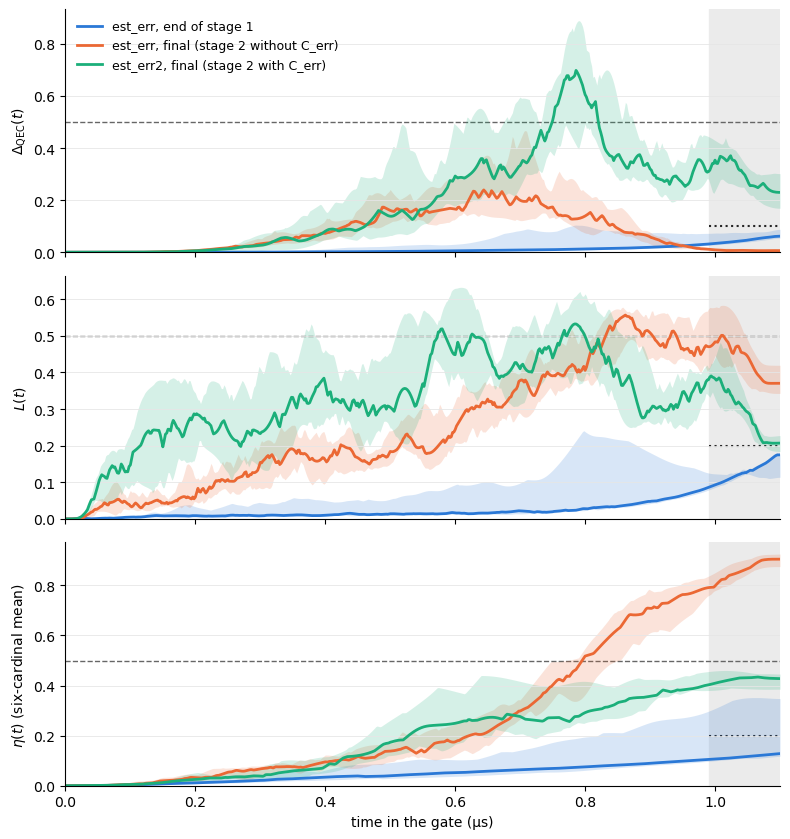

In [9]:
cases = [("est_err, end of stage 1", lambda s, k: trH[f"{name1[s]}/stage1/{k}"], COLORS[0]),
         ("est_err, final (stage 2 without C_err)", lambda s, k: trH[f"{name1[s]}/final/{k}"], COLORS[1]),
         ("est_err2, final (stage 2 with C_err)", lambda s, k: tr2[f"{name2[s]}/final/{k}"], COLORS[2])]
t = trH[f"{name1[seeds2[0]]}/final/t"]
fig, axes = plt.subplots(3, 1, figsize=(8, 8.5), sharex=True)
for ax, (key, label, peak, tail) in zip(axes, panels):
    ax.axvspan(S.TAIL_FRAC * T_g, T_g, color="0.92", zorder=0)
    ax.axhline(peak, color="0.4", lw=1, ls="--", zorder=1)
    ax.hlines(tail, S.TAIL_FRAC * T_g, T_g, color="0.15", lw=1.5, ls=":", zorder=1)
    for lab, get, c in cases:
        Y = np.stack([get(s, key) for s in seeds2])
        lo, med, hi = np.percentile(Y, [25, 50, 75], axis=0)
        ax.fill_between(t, lo, hi, color=c, alpha=0.18, lw=0)
        ax.plot(t, med, color=c, lw=2, label=lab)
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[-1].set_xlabel("time in the gate (μs)")
axes[-1].set_xlim(0, T_g)
fig.tight_layout()
fig.savefig("figures/est/fig_est_gate_seeds_H_stages.png", dpi=150)
plt.show()

*Figure 2.* The three metrics over the 1.1 μs gate for the 21 H gates at three points: the end of stage 1 (blue), the
final est_err pulse (orange), and the final est_err2 pulse of Appendix B.4 (green). Lines are the median over the 21 seeds
and the shaded bands the middle half (25th to 75th percentile). Stage 1 keeps all three metrics low but leaves the
gate unfinished ($F_1$ 0.24–0.83). Stage 2 without $C_{\rm err}$ finishes the gate and η climbs to about 0.9 by
the end. With $C_{\rm err}$ kept on, η stays below 0.5, but $\Delta_{\rm QEC}$ rises over the whole second half
and $L$ is higher for most of the gate, lower only near the end.
In short, at 1.1 μs the H gate could be finished or kept transparent, but not both.
*Symbols:* as in Figure 1; the bars are those of the rule.

## 7.2 Why a longer H gate: the two chips

The EsT method comes from Roy, Wetherbee & Fatemi (the "EST paper"), whose chip is not the one used here. This
notebook uses the Shirol chip (the d2 gate's chip). The table puts the two side by side.

| | EST paper chip | Shirol chip (this notebook) |
|---|---|---|
| storage–transmon dispersive shift $\lvert\chi\rvert/2\pi$ | **3.66 MHz** | **1.12 MHz** (g–e); 0.95 MHz (e–f) |
| time to resolve one photon, $1/(\lvert\chi\rvert/2\pi)$ | 0.27 μs | 0.89 μs |
| transmon anharmonicity $\lvert\alpha\rvert/2\pi$ | 180 MHz | 134 MHz |
| storage self-Kerr $\lvert K\rvert/2\pi$ | 22 kHz | 3.3 kHz |
| second-order dispersive shift $/2\pi$ | $\chi'$ 39 kHz | $\chi'_q$ 1.9 kHz |
| storage / transmon $T_1$ | 180 / 70 μs | 136 / 50 μs |
| kitten code $\lvert 0_L\rangle$, $\lvert 1_L\rangle$ | $(\lvert0\rangle+\lvert4\rangle)/\sqrt2$, $\lvert2\rangle$ | $(\lvert1\rangle+\lvert5\rangle)/\sqrt2$, $\lvert3\rangle$ |
| drive cap per drive | 25 rad/μs ($2\pi\cdot$4 MHz) | 25 rad/μs |
| drive bands | ±50 MHz (both drives) | ±27 MHz (storage), ±33 MHz (transmon) |
| time step | 1 ns | 2 ns |
| H gate length $T$ | 1.0 μs | 1.1 μs (first attempt), 2 μs (§7, 2026-11-02) |
| gate length in units of $1/\chi$, $\chi T/2\pi$ | 3.7 | 1.2 (1.1 μs), 2.2 (2 μs) |

*Table 6.* Chip and pulse settings. EST values: `EST/device.py` (the paper's Table I and App. C). Shirol values:
`AQEC/device.py` (Shirol et al., Table I) and `DGRAPE/recipe.py` (d2's drive limits). Signs differ between the two
papers' conventions, so magnitudes are shown.
*Symbols:* χ, dispersive shift (how much the transmon frequency moves per photon in the storage); α,
anharmonicity; K, self-Kerr; $T_1$, energy decay time; $T$, gate length.

**Why χ sets the gate length.** An H gate on the kitten code must treat each photon number differently: it gives
$\lvert1\rangle$, $\lvert3\rangle$ and $\lvert5\rangle$ their own phases and mixes them in its own way. The only
handle on the photon number is the transmon. Its frequency moves by χ per photon, so a drive can address one
photon number only if it runs long enough to tell frequencies χ apart, which takes about $1/\chi$. On the Shirol chip
χ is 3.3 times smaller than on the EST chip, so the same operation needs about 3.3 times longer. At 1.1 μs the H gate
here lasted only 1.2 units of $1/\chi$, against 3.7 for the EST paper's 1.0 μs H gate, which was its *most*
transparent gate. That is why §7 lengthens the H gate.

The drive cap is the same on both chips, so drive strength is not the difference. The narrower drive bands here
also slow the gate somewhat. **Caveat:** matching the EST gate's 3.7 units of $1/\chi$ would take about 3.3 μs.
The 2 μs gate (2.2 units) closes about half the gap, and it pays for the extra time with more photon loss in the
open system.


## 7.3 What changes at 2 μs

Only the gate length: $T$ = 2 μs, so N = 1000 steps of 2 ns (`--duration-us 2` on `DGRAPE/train_est_gate.py`
and `DGRAPE/est_gate_seeds.py`). Everything else is §1's: the est_err cost and its two stages (2000 iterations each),
d2's bands, ramp, box, cap and smooth start, training at 20 storage levels and scoring at 24, and the rule. The
cost terms $C_2$, $C_3$, $C_4$ are time averages, so their weights need no rescaling.

Two consequences of the longer gate:
- The tail, $t \ge 0.9\,T$, is now the last 0.2 μs instead of the last 0.11 μs.
- A 2 μs gate loses more photons, which the closed-system rule does not see. §7.7 reports the open system.

Seeds 0–49 were trained in two waves of 25 (0–24, then 25–49), 25 runs at a time with one BLAS thread each.
Wave 1 took 3.6 h, against about 1.5 h at 1.1 μs. Wave 2 took 7.5 h for the same 2000 + 2000 iterations
(447 min per run against 215): each run went at half the speed, which changes the time, not the pulses. The second wave was the user's request
(2026-11-02), after the peak ΔQEC bar was set to 0.4; the rule and the ranking are unchanged and cover all 50.


## 7.4 All runs


In [10]:
colsT = {"seed": "seed", "wave": "wave", "tier": "tier", "F1": "F1", "score": "score", "peak_score": "peak score",
         "dqec_mean": "mean ΔQEC", "L_mean": "mean L", "eta_mean": "mean η", "dqec_peak": "peak ΔQEC",
         "L_peak": "peak L", "eta_peak": "peak η", "dqec_tail": "tail ΔQEC", "L_tail": "tail L",
         "eta_tail": "tail η", "L_T": "L(T)", "trunc_spread": "|F1(28)-F1(24)|", "max_active_fock": "max Fock"}
tabT = finT.reset_index().sort_values("seed")
tabT["wave"] = np.where(tabT.seed < 25, 1, 2)
fmtT = {c: "{:.3f}" for c in colsT.values() if c not in ("seed", "wave", "tier")}
fmtT.update({"F1": "{:.5f}", "|F1(28)-F1(24)|": "{:.1e}", "max Fock": "{:.0f}"})
display(tabT[list(colsT)].rename(columns=colsT).style.format(fmtT).hide(axis="index")
        .set_caption("Table 7. Every trained H seed at 2 μs, final pulses, closed system at n_c 24"))


seed,wave,tier,F1,score,peak score,mean ΔQEC,mean L,mean η,peak ΔQEC,peak L,peak η,tail ΔQEC,tail L,tail η,L(T),|F1(28)-F1(24)|,max Fock
0,1,closed,0.99939,0.124,0.518,0.055,0.124,0.193,0.257,0.552,0.745,0.015,0.317,0.700,0.215,1.8e-07,14
1,1,closed,0.99978,0.109,0.325,0.074,0.135,0.119,0.344,0.358,0.273,0.004,0.260,0.220,0.282,2.9e-12,10
2,1,closed,0.99967,0.078,0.338,0.035,0.111,0.089,0.241,0.384,0.390,0.004,0.271,0.348,0.240,8.6e-12,11
3,1,closed,0.99961,0.129,0.439,0.093,0.151,0.144,0.433,0.474,0.409,0.010,0.373,0.372,0.339,1.1e-12,10
4,1,closed,0.99929,0.127,0.314,0.062,0.185,0.133,0.260,0.426,0.256,0.011,0.156,0.220,0.151,2.7e-09,13
5,1,closed,0.99975,0.087,0.224,0.033,0.127,0.101,0.163,0.272,0.238,0.001,0.146,0.218,0.133,3.7e-15,10
6,1,closed,0.99958,0.101,0.403,0.070,0.131,0.103,0.568,0.332,0.309,0.003,0.288,0.273,0.311,2.7e-13,10
7,1,closed,0.99961,0.084,0.338,0.048,0.124,0.078,0.444,0.377,0.193,0.003,0.161,0.165,0.177,9.7e-12,11
8,1,open,0.99820,0.210,0.524,0.077,0.253,0.299,0.242,0.516,0.814,0.018,0.387,0.777,0.288,1.8e-07,14
9,1,open,0.99900,0.123,0.428,0.100,0.182,0.087,0.629,0.470,0.185,0.005,0.261,0.168,0.256,2.6e-09,13


*Table 7.* One row per final H pulse at 2 μs, as Table 1; "wave" 1 is seeds 0–24, 2 is seeds 25–49. No pulse
parks. Seed 29 trains against the truncation wall: $F_1$ 0.9997 at the 20 storage levels it was trained at, 0.016
at 24 (it reaches Fock 23). Of the other 49, five end just under EST's "closed" bar ($F_1$ 0.9982–0.9990, tier
open) and 44 close. They read the same at 24 and 28 storage levels (to 5e-6).
*Symbols:* as in Table 1; peak score = (peak ΔQEC + peak L + peak η)/3; tail = mean over $t \ge 0.9\,T$ = the
last 0.2 μs.


## 7.5 Selection


In [11]:
pT = pickT.copy()
pT["name"] = [f"seed {s}" for s in pT.seed]
showT = pT[["name", "rank", "score", "peak_score", "F1"] + checks]
showT = showT.assign(**{c: showT[c].map({True: "✓", False: "✗"}) for c in checks})
display(showT.style.format({"score": "{:.3f}", "peak_score": "{:.3f}", "F1": "{:.5f}", "rank": "{:.0f}"},
                           na_rep="").hide(axis="index")
        .set_caption("Table 8. The rule for H at 2 μs, check by check"))
print("failing each check:", (~pickT[checks].astype(bool)).sum().to_dict())
print(f"{len(candT)} candidates:", [int(s) for s in candT.seed])


name,rank,score,peak_score,F1,F1_ok,dqec_peak_ok,L_peak_ok,eta_peak_ok,dqec_tail_ok,L_tail_ok,eta_tail_ok,trunc_ok
seed 17,1,0.086,0.279,0.99968,✓,✓,✓,✓,✓,✓,✓,✓
seed 27,2,0.111,0.299,0.99960,✓,✓,✓,✓,✓,✓,✓,✓
seed 32,,0.082,0.302,0.99962,✓,✓,✓,✓,✓,✗,✓,✓
seed 7,,0.084,0.338,0.99961,✓,✗,✓,✓,✓,✓,✓,✓
seed 5,,0.087,0.224,0.99975,✓,✓,✓,✓,✓,✓,✗,✓
seed 35,,0.092,0.326,0.99968,✓,✗,✓,✓,✓,✓,✓,✓
seed 21,,0.093,0.261,0.99963,✓,✓,✓,✓,✓,✓,✗,✓
seed 41,,0.094,0.296,0.99956,✓,✓,✓,✓,✓,✗,✓,✓
seed 34,,0.101,0.349,0.99947,✓,✓,✓,✓,✓,✓,✗,✓
seed 23,,0.104,0.350,0.99920,✓,✗,✓,✓,✓,✓,✓,✓


failing each check: {'F1_ok': 1, 'dqec_peak_ok': 23, 'L_peak_ok': 15, 'eta_peak_ok': 19, 'dqec_tail_ok': 1, 'L_tail_ok': 40, 'eta_tail_ok': 40, 'trunc_ok': 1}
2 candidates: [17, 27]


*Table 8.* As Table 2, for H at 2 μs, with the peak ΔQEC bar at 0.4 (Table 2: 0.5). ✓ means the check
passes. Seeds 7, 23, 35 and 45 fail only that bar (peak ΔQEC 0.444, 0.4015, 0.471, 0.449). Rank is given to the seeds that pass every
check, in order of mean score (lowest first); the rows below them are sorted by the number of failed checks.
*Symbols:* as in Table 2.


In [12]:
H40 = S.tag(40, "H")                                         # the closest 1.1 us H gate (Table B3)
rowsT = []
for lab, r in ([(f"H 2 μs, {lab_T(n)}", finT.loc[n]) for n in TOP_T]
               + [("H 1.1 μs, seed 40 (not a candidate)", finH.loc[H40]), ("X pick, 1.1 μs (seed 24)", fin.loc[X_PICK])]):
    rowsT.append({"gate": lab, "F1": r.F1, "score": r.score, "peak score": (r.dqec_peak + r.L_peak + r.eta_peak) / 3.0,
                  "mean ΔQEC": r.dqec_mean, "mean L": r.L_mean, "mean η": r.eta_mean,
                  "peak ΔQEC": r.dqec_peak, "peak L": r.L_peak, "peak η": r.eta_peak,
                  "t of peak ΔQEC (μs)": r.dqec_peak_t, "t of peak L (μs)": r.L_peak_t,
                  "t of peak η (μs)": r.eta_peak_t,
                  "tail ΔQEC": r.dqec_tail, "tail L": r.L_tail, "tail η": r.eta_tail, "L(T)": r.L_T,
                  "η(T)": r.eta_T, "max Fock": r.max_active_fock})
topT = pd.DataFrame(rowsT).set_index("gate")
display(topT.T.style.format("{:.4f}")
        .set_caption("Table 9. The two H candidates at 2 μs and the best gate that passes at 0.5 only, with the best "
                     "1.1 μs H gate and the X pick for scale"))


gate,"H 2 μs, seed 17 (rank 1)","H 2 μs, seed 27 (rank 2)","H 2 μs, seed 7 (passes at 0.5 only)","H 1.1 μs, seed 40 (not a candidate)","X pick, 1.1 μs (seed 24)"
F1,0.9997,0.9996,0.9996,0.9990,0.9987
score,0.0855,0.1110,0.0835,0.1995,0.1104
peak score,0.2787,0.2987,0.3378,0.5436,0.3220
mean ΔQEC,0.0604,0.0672,0.0483,0.0564,0.0536
mean L,0.1332,0.1592,0.1245,0.2302,0.1983
mean η,0.0629,0.1065,0.0777,0.3118,0.0792
peak ΔQEC,0.3639,0.3109,0.4437,0.1736,0.2324
peak L,0.3357,0.4094,0.3769,0.5732,0.4908
peak η,0.1366,0.1757,0.1929,0.8838,0.2427
t of peak ΔQEC (μs),1.2300,1.0100,1.2200,0.6060,0.5940


*Table 9.* The two candidates (seeds 17 and 27), then the best-scoring gate that passes every bar of §1 but
not the lowered peak ΔQEC bar (seed 7). For scale: the closest 1.1 μs H gate (seed 40, Table B3),
which fails four bars, and the X pick of §6. "t of peak" is the time at which each metric reaches its maximum; the
2 μs gate ends at 2.0 μs.
*Symbols:* as in Table 1.


## 7.6 The three metrics over the gate


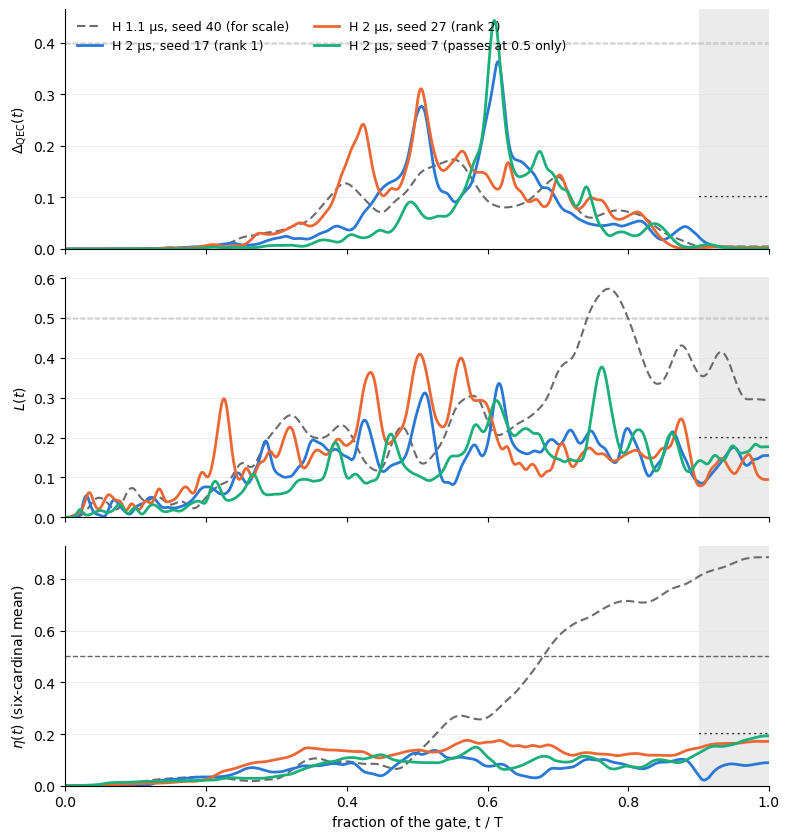

In [13]:
H_COLOR = "#6b6b6b"
fig, axes = plt.subplots(3, 1, figsize=(8, 8.5), sharex=True)
T2 = trT[f"{TOP_T[0]}/final/t"][-1]
for ax, (key, label, _, tail) in zip(axes, panels):
    peak = S.peak_max("H", 2.0)[key]                          # 0.4 for dQEC (user, 2026-11-02)
    ax.axvspan(S.TAIL_FRAC, 1.0, color="0.92", zorder=0)
    ax.axhline(peak, color="0.4", lw=1, ls="--", zorder=1)
    ax.hlines(tail, S.TAIL_FRAC, 1.0, color="0.15", lw=1.5, ls=":", zorder=1)
    ax.plot(trH[f"{H40}/final/t"] / T_g, trH[f"{H40}/final/{key}"], color=H_COLOR, lw=1.5, ls=(0, (4, 2)),
            label="H 1.1 μs, seed 40 (for scale)")
    for c, n in zip(COLORS, TOP_T):
        ax.plot(trT[f"{n}/final/t"] / T2, trT[f"{n}/final/{key}"], color=c, lw=2,
                label=f"H 2 μs, {lab_T(n)}")
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
axes[-1].set_xlabel("fraction of the gate, t / T")
axes[-1].set_xlim(0, 1)
fig.tight_layout()
fig.savefig("figures/est/fig_est_gate_seeds_H_T2_top.png", dpi=150)
plt.show()


*Figure 3.* The three transparency metrics over the gate for the two 2 μs candidates (seeds 17 and 27) and the best gate that passes at 0.5 only (seed 7) (solid) and the
closest 1.1 μs H gate (gray, dashed). Time is shown as a fraction of each gate's length ($T$ = 2 μs and 1.1 μs),
so the two line up. The gray band is the tail, $t \ge 0.9\,T$; the dashed line is the peak bar (0.4 for ΔQEC, 0.5 for L and η) and the dotted
line in the band is the tail bar, which applies to the band's mean. At 2 μs η stays below 0.2 over the whole
gate, while the 1.1 μs gate's η passes 0.5 at about two thirds of the gate. The ΔQEC peaks sit near the middle
of the 2 μs gates (0.5–0.6 T), and L ends at 0.09–0.18, below its tail bar.
*Symbols:* as in Figure 1.


## 7.7 The candidates in the open system


In [14]:
opT = pd.read_csv(PT["open_csv"])
opT["gate"] = [f"H 2 μs, {lab_T(n)}" for n in opT.name]
opX = pd.read_csv(S.OPEN_CSV)
opX = opX[opX.name == X_PICK].assign(gate="X pick, 1.1 μs (seed 24)")
cols_op = ["F_pro_decay", "F_pro_all", "F_repaired", "repair_gain", "losses_per_gate", "f_midgate_loss_repaired"]
display(pd.concat([opT, opX]).set_index("gate")[cols_op].style
        .format({"F_pro_decay": "{:.5f}", "F_pro_all": "{:.5f}", "F_repaired": "{:.5f}", "repair_gain": "{:+.2%}",
                 "losses_per_gate": "{:.4f}", "f_midgate_loss_repaired": "{:.3f}"})
        .set_caption("Table 10. Open-system scores (n_c 24) of the 2 μs H gates of Table 9"))


,F_pro_decay,F_pro_all,F_repaired,repair_gain,losses_per_gate,f_midgate_loss_repaired
gate,,,,,,
"H 2 μs, seed 17 (rank 1)",0.95013,0.93725,0.98106,+3.09%,0.0439,0.746
"H 2 μs, seed 27 (rank 2)",0.95038,0.93691,0.98401,+3.36%,0.0450,0.805
"H 2 μs, seed 7 (passes at 0.5 only)",0.95084,0.93872,0.98096,+3.01%,0.0433,0.724
"H 2 μs, seed 23 (passes at 0.5 only)",0.95001,0.93673,0.98091,+3.09%,0.0445,0.752
"X pick, 1.1 μs (seed 24)",0.96706,0.95733,0.98699,+1.99%,0.0268,0.851


*Table 10.* As Table 4, for the 2 μs H gates of Table 9 and seed 23 (passes at 0.5 only; scored with the
first wave and kept), with the X pick for scale (a different gate and a
shorter one). These numbers are reported only and play no part in the selection.
*Symbols:* as in Table 4; F_pro is the process fidelity against the ideal H (against X for the X pick).


## 7.8 Conclusions for H

**At 2 μs the H gate passes the rule. Over 50 seeds the pick is still seed 17**
(`pulses/dgrape/u_H_est_err_closed_T2_s17.npy`), with **seed 27** as the runner-up
(`pulses/dgrape/u_H_est_err_closed_T2_s27.npy`). At 1.1 μs no seed in 50 passed (§7.1).

- **How the 50 starts ended.** None parks. Wave 1 made 25 gates. Wave 2 made 24, and seed 29 trained against the
  truncation wall (as X's seed 9 did at 1.1 μs). The 49 gates have $F_1$ 0.9982–0.9998, 44 of them at or above
  EST's 0.999. 15 starts (11 in wave 1, 4 in wave 2) are still parked after stage 1, and stage 2 drives every one
  of them out. At 1.1 μs, 28 of 50 starts ended parked.
- **The bar on peak ΔQEC (the user's decision, 2026-11-02).** At §1's bars six seeds pass, three per wave (7, 17,
  23 and 27, 35, 45). With the peak ΔQEC bar at 0.4, two remain: seed 17 from wave 1 and seed 27 from wave 2.

  | | seed | score | mean ΔQEC / L / η | peak ΔQEC / L / η | tail ΔQEC / L / η | F1 |
  |---|---|---|---|---|---|---|
  | **pick (rank 1)** | **17** | **0.086** | 0.060 / 0.133 / 0.063 | 0.36 / 0.34 / 0.14 | 0.005 / 0.14 / 0.07 | 0.9997 |
  | rank 2 | 27 | 0.111 | 0.067 / 0.159 / 0.106 | 0.31 / 0.41 / 0.18 | 0.003 / 0.12 / 0.16 | 0.9996 |
  | passes at 0.5 only | 7 | 0.084 | 0.048 / 0.124 / 0.078 | 0.44 / 0.38 / 0.19 | 0.003 / 0.16 / 0.16 | 0.9996 |
  | passes at 0.5 only | 35 | 0.092 | 0.074 / 0.132 / 0.071 | 0.47 / 0.32 / 0.19 | 0.004 / 0.13 / 0.08 | 0.9997 |
  | passes at 0.5 only | 23 | 0.104 | 0.071 / 0.166 / 0.077 | 0.40 / 0.49 / 0.16 | 0.002 / 0.17 / 0.15 | 0.9992 |
  | passes at 0.5 only | 45 | 0.107 | 0.078 / 0.168 / 0.075 | 0.45 / 0.40 / 0.16 | 0.005 / 0.14 / 0.15 | 0.9996 |

  - **Seed 17 stays the pick.** It has the lower mean score of the two candidates (0.086 against
    0.111), the lower peak score (0.279 against 0.299),
    the lower η at the end (tail 0.07 against 0.16; η(T)
    0.09 against 0.17) and the higher $F_1$.
  - **Seed 27 is better on ΔQEC and on L at the end:** peak ΔQEC 0.31 against
    0.36, tail L 0.12 against 0.14, L(T)
    0.09 against 0.16. Its mean score equals the X pick's (0.111
    against 0.110).
  - **The lowest mean score of all 49 gates, seed 32 (0.082), fails only the L tail**
    (0.28), and seed 7 (0.084) fails only the 0.4 bar. So the bars, not the
    ranking, decide the pick.
- **No gate with a peak ΔQEC of 0.3 or less passes** (checked, not a rule). There are now 19 such gates (8 in wave 1,
  11 in wave 2), and every one fails a tail bar: seeds 4, 5 and 21 only the η tail
  (0.220, 0.218, 0.260), seed 41 only the L tail
  (0.267). The nearest candidate is seed 27, at 0.311.
- **The longer gate fixes the end of the gate.** The medians over the 49 gates at 2 μs against the 21 at 1.1 μs:
  - tail η 0.37 against 0.86, and peak η 0.41 against 0.91;
  - tail L 0.28 against 0.43, and peak L 0.44 against 0.60;
  - mean score 0.11 against 0.22;
  - peak ΔQEC 0.34 against 0.44. Over wave 1 alone it was 0.43,
    so this one moves with the seeds rather than with the gate length.
- **The bars that fail most are the tails and the ΔQEC peak.** Of the 49 gates, 39 fail the η tail and 39 the L
  tail; 22 fail the ΔQEC peak at 0.4, 18 the η peak and 14 the L peak. No gate fails the ΔQEC tail or $F_1$; only
  seed 29 fails the truncation check.
- **Every run stopped at the 2000-iteration limit in both stages**, so these are not converged gates.
- **Open system (Table 10): the longer gate pays in photon loss.** The comparison is with the X pick, a different and
  shorter gate.
  - **The gate alone scores lower.** For seed 17, F_pro is 0.9501 with decay only (X pick
    0.9671) and 0.9373 with all channels (X pick 0.9573).
  - **More photons are lost per gate:** 0.044 against 0.027, which scales with
    the 1.8× longer gate.
  - **There is more to repair, so the ideal repair gains more**, +3.1% against +2.0%.
    The repaired gate still ends lower, at 0.981 against 0.987.
  - **A photon lost mid-gate repairs to 0.75** against 0.85,
    even though the closed-system metrics are lower, so the three closed-system metrics do not predict this repair.
  - **Seed 27 is as good alone and repairs better.** Its F_pro is 0.9504 (decay) and
    0.9369 (all channels), close to seed 17's. A photon lost mid-gate repairs to
    0.81 against 0.75, the ideal repair gains
    +3.4% against +3.1%, and the repaired gate ends at 0.984 against
    0.981. This fits its lower L at the end (L(T) 0.09 against
    0.16). The rule did not look at repair, so this does not change the pick.
  - **All four 2 μs gates of Table 10 lie within 0.0007 of seed 17 on F_pro**; on the mid-gate repair seeds 7 and
    23 score 0.72 and 0.75.
- **Caveat on the length.** 2 μs is 2.2 units of $1/\chi$, still short of the EST paper's 3.7 (§7.2).

**Next.** Seed 17 is the H pick by the rule. Seed 27 is the alternative if the gate is to be followed by a repair
(FWM tails): it has the lower ΔQEC peak and L at the end, and the better mid-gate repair, at a higher η at the end.
- **More seeds are unlikely to help:** 50 seeds gave two candidates, and the gates with a ΔQEC peak under 0.3 all
  fail a tail bar.
- **A tail cost:** the η and L tails are the bars that most gates fail, so a cost on η and L near $T$ would target
  them directly.
- **A χ-matched H gate (about 3.3 μs)** would test whether more time keeps helping, at a further cost in photon loss.


# Appendix A. Commands and decisions

```bash
python DGRAPE/est_gate_seeds.py run --wave 1 --jobs 25     # trains into ~/fwm_runs/est_err_seeds
python DGRAPE/est_gate_seeds.py run --wave 2 --jobs 25     # seeds 25-49, same settings
python DGRAPE/est_gate_seeds.py status
python DGRAPE/est_gate_seeds.py summarize                 # -> tables/est_gate_seeds_X_{runs,pick}.csv, _traces.npz
python DGRAPE/est_gate_seeds.py open_score --top 3        # -> tables/est_gate_seeds_X_open.csv
python validation/test_est_gate.py -v                     # includes the est_err weight pin and gradient check

# §7, the H gate: the same commands with --gate H (runs in ~/fwm_runs/est_err_seeds_H)
python DGRAPE/est_gate_seeds.py run --gate H --wave 1 --jobs 25
python DGRAPE/est_gate_seeds.py run --gate H --wave 2 --jobs 25
python DGRAPE/est_gate_seeds.py summarize --gate H        # -> tables/est_gate_seeds_H_{runs,pick}.csv, _traces.npz
# §7.4, C_err kept in stage 2: the 21 H gates resumed from their stage-1 pre-images (--start-stage 2)
python DGRAPE/est_gate_seeds.py run --gate H --variant est_err2 --jobs 25   # ~52 min, ~/fwm_runs/est_err2_seeds_H
python DGRAPE/est_gate_seeds.py summarize --gate H --variant est_err2      # -> tables/est_gate_seeds_H_err2_*
# §7.3-§7.8, H at 2 us: seeds 0-49 in two waves (3.6 h and 7.5 h, ~/fwm_runs/est_err_seeds_H_T2)
python DGRAPE/est_gate_seeds.py run --gate H --duration-us 2 --wave 1 --jobs 25
python DGRAPE/est_gate_seeds.py run --gate H --duration-us 2 --wave 2 --jobs 25   # seeds 25-49
python DGRAPE/est_gate_seeds.py summarize --gate H --duration-us 2        # -> tables/est_gate_seeds_H_T2_*
python DGRAPE/est_gate_seeds.py open_score --gate H --duration-us 2 --top 3 --extra-seeds 7 23
```

**Decisions (2026-10-29, the user's).**
- Cost and stage weights: `est_optimization.ipynb` §7, at most 50 seeds.
- Bars: $F_1 > 0.99$. Peaks ≤ 0.5 for all three metrics. Tails $\Delta_{\rm QEC}\le0.1$, $L\le0.2$, $\eta\le0.2$.
- Tail = the mean over $t\ge0.9\,T$.
- Ranking by the plain mean of the three time means.
- Waves of 25 with an early stop at ≥ 3 candidates.
- An open-system score for the top 3 only.

**Decision (2026-10-29, the user's, after wave 1).** Wave 2 was run although wave 1 had already met the stop rule.
The cost, the bars and the ranking were not changed. The ranking covers all 50 seeds, and the open-system
score was redone for the new top 3 (seeds 24, 45, 38).

**Decisions (2026-11-01, the user's): the H gate (§7).**
- The same cost, seeds, limits and bars as X.
- Candidates ranked by peak score = (peak $\Delta_{\rm QEC}$ + peak $L$ + peak $\eta$)/3, lowest first.
- Both waves run (50 seeds), with no stop rule.
- No H reference gate.

**Decision (2026-11-02, the user's, after the H search gave no candidate).** Rerun stage 2 of every H gate with $C_{\rm err}$ kept on (variant `est_err2`: stage 2 = (1, 0.1, 0, 1, 0.3)), from each run's stage-1 pre-image, under the same rule. It gave no candidate either.

**Decisions (2026-11-02, the user's): the H gate at 2 μs (§7.2–§7.8).**
- Gate length 2 μs (N = 1000); everything else as the 1.1 μs search (est_err cost, limits, start, bars).
- 25 seeds (0–24), one wave.
- Candidates ranked by the mean score (the user's "low averages for the 3 ET metrics"); peak score reported too.
- §7 rewritten around the 2 μs search, with the 1.1 μs record condensed in §7.1 and moved in full to Appendix B.
- A chip comparison table in §7 explaining why the gate needs to be longer (§7.2).
- The three candidates at §1's bars (seeds 7, 17, 23) copied to
  `pulses/dgrape/u_H_est_err_closed_T2_s{7,17,23}.npy` (with `x_` pre-images and `.json`).

**Decision (2026-11-02, the user's, after the first look at the 2 μs results).** The peak ΔQEC bar for the 2 μs H
search is lowered from 0.5 to 0.4 (`est_gate_seeds.PEAK_MAX_BY`); everything else is unchanged. One candidate
remains, seed 17, which is the H pick. A bar of 0.3 was checked first and leaves no candidate. Seeds 7 and 23 stay in
the open-system table (Table 10) for comparison.

**Decision (2026-11-02, the user's, after the 0.4 decision).** A second wave of 25 seeds (25–49) for the
2 μs H gate. The rule (peak ΔQEC ≤ 0.4) and the ranking are unchanged and cover all 50 seeds.
Two candidates: seed 17 (still the pick) and seed 27, copied to `pulses/dgrape/u_H_est_err_closed_T2_s27.npy`
(with `x_` and `.json`). The open-system table keeps seeds 7 and 23 (`--extra-seeds 7 23`).


# Appendix B. The H gate at 1.1 μs, full record

This is the full record of the first H search (§7.1), unchanged except for the numbering. It used 1.1 μs, the X
search's settings, and ranking by **peak score** = (peak $\Delta_{\rm QEC}$ + peak $L$ + peak $\eta$)/3, lowest first
(the user's choice, 2026-11-01). Both waves were run (seeds 0–49), and there is no H reference gate. For scale,
Table B3 and Figure B1 show the X pick (seed 24) next to the H gates.


## B.1 All runs

In [15]:
colsH = {"seed": "seed", "tier": "tier", "F1": "F1", "peak_score": "peak score", "score": "score",
         "dqec_peak": "peak ΔQEC", "L_peak": "peak L", "eta_peak": "peak η", "dqec_mean": "mean ΔQEC",
         "L_mean": "mean L", "eta_mean": "mean η", "dqec_tail": "tail ΔQEC", "L_tail": "tail L",
         "eta_tail": "tail η", "L_T": "L(T)", "trunc_spread": "|F1(28)-F1(24)|", "max_active_fock": "max Fock"}
tabH = finH.reset_index().sort_values("seed")
fmtH = {c: "{:.3f}" for c in colsH.values() if c not in ("seed", "tier")}
fmtH.update({"F1": "{:.5f}", "|F1(28)-F1(24)|": "{:.1e}", "max Fock": "{:.0f}"})
display(tabH[list(colsH)].rename(columns=colsH).style.format(fmtH).hide(axis="index")
        .set_caption("Table B1. Every trained H seed at 1.1 μs, final pulses, closed system at n_c 24"))

seed,tier,F1,peak score,score,peak ΔQEC,peak L,peak η,mean ΔQEC,mean L,mean η,tail ΔQEC,tail L,tail η,L(T),|F1(28)-F1(24)|,max Fock
0,open,0.99838,0.722,0.250,0.645,0.576,0.946,0.142,0.267,0.341,0.009,0.381,0.931,0.335,3.4e-08,13
1,parked,0.33135,0.007,0.003,0.000,0.001,0.020,0.000,0.000,0.010,0.000,0.001,0.019,0.001,2.7e-15,5
2,parked,0.33135,0.007,0.003,0.000,0.001,0.020,0.000,0.000,0.010,0.000,0.001,0.019,0.001,7.4e-15,5
3,parked,0.33135,0.007,0.003,0.000,0.001,0.020,0.000,0.000,0.010,0.000,0.001,0.019,0.001,8.9e-15,5
4,parked,0.33135,0.007,0.003,0.000,0.001,0.020,0.000,0.000,0.010,0.000,0.001,0.019,0.001,1.6e-14,5
5,open,0.99725,0.550,0.188,0.174,0.586,0.889,0.062,0.250,0.253,0.007,0.443,0.820,0.416,1.2e-10,12
6,parked,0.33135,0.007,0.003,0.000,0.001,0.020,0.000,0.000,0.010,0.000,0.001,0.019,0.001,7.1e-15,5
7,open,0.99832,0.556,0.209,0.269,0.544,0.856,0.078,0.212,0.338,0.007,0.327,0.827,0.292,2.5e-09,12
8,parked,0.33135,0.007,0.003,0.000,0.001,0.020,0.000,0.000,0.010,0.000,0.001,0.019,0.001,6.6e-15,5
9,wall,0.01727,4.456,2.506,10.796,0.966,1.606,5.651,0.790,1.077,4.520,0.950,1.384,0.964,4.5e-03,23


*Table B1.* One row per final H pulse, as Table 1. The **peak score** is the mean of the three peaks, and it is the
ranking key for H. The tiers are those of Table 1 (parked, open, closed, wall).
*Symbols:* as in Table 1; peak = $\max_t$ over the whole gate.

## B.2 Selection

In [16]:
pH = pickH.copy()
pH["name"] = [f"seed {s}" for s in pH.seed]
showH = pH[["name", "rank", "peak_score", "score", "F1"] + checks]
showH = showH.assign(**{c: showH[c].map({True: "✓", False: "✗"}) for c in checks})
display(showH.style.format({"peak_score": "{:.3f}", "score": "{:.3f}", "F1": "{:.5f}", "rank": "{:.0f}"},
                           na_rep="").hide(axis="index").set_caption("Table B2. The rule for H at 1.1 μs, check by check"))
okH = pickH[pickH.name.isin(gatesH.index)]
print(f"{len(gatesH)} H gates; failing each check:", (~okH[checks].astype(bool)).sum().to_dict())
candH = pickH[pickH["rank"].notna()].sort_values("rank")
print(f"{len(candH)} H candidates")

name,rank,peak_score,score,F1,F1_ok,dqec_peak_ok,L_peak_ok,eta_peak_ok,dqec_tail_ok,L_tail_ok,eta_tail_ok,trunc_ok
seed 13,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 28,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 35,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 15,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 10,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 4,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 49,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 2,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 30,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓
seed 36,,0.007,0.003,0.33135,✗,✓,✓,✓,✓,✓,✓,✓


21 H gates; failing each check: {'F1_ok': 0, 'dqec_peak_ok': 7, 'L_peak_ok': 21, 'eta_peak_ok': 21, 'dqec_tail_ok': 0, 'L_tail_ok': 21, 'eta_tail_ok': 21, 'trunc_ok': 0}
0 H candidates


*Table B2.* As Table 2, for H. A rank would be given only to seeds that pass every check, in order of peak score;
no H seed does.
*Symbols:* as in Table 2.

In [17]:
def peak_score(r):
    return (r.dqec_peak + r.L_peak + r.eta_peak) / 3.0

# no candidates: the three gates with F1 >= 0.99 and the lowest peak score, for inspection only
NEAR_H = list(gatesH[gatesH.F1 >= S.F1_MIN].sort_values("peak_score").index[:3])
rowsH = []
for n, r, s1 in [(n, finH.loc[n], st1H) for n in NEAR_H] + [(X_PICK, fin.loc[X_PICK], st1)]:
    rowsH.append({"gate": f"H seed {r.seed}" if n != X_PICK else "X pick (seed 24)", "F1": r.F1,
                  "peak score": peak_score(r), "score": r.score,
                  "peak ΔQEC": r.dqec_peak, "peak L": r.L_peak, "peak η": r.eta_peak,
                  "t of peak ΔQEC (μs)": r.dqec_peak_t, "t of peak L (μs)": r.L_peak_t,
                  "t of peak η (μs)": r.eta_peak_t,
                  "mean ΔQEC": r.dqec_mean, "mean L": r.L_mean, "mean η": r.eta_mean,
                  "tail ΔQEC": r.dqec_tail, "tail L": r.L_tail, "tail η": r.eta_tail, "L(T)": r.L_T,
                  "max Fock": r.max_active_fock, "F1 after stage 1": s1.loc[n].F1 if n in s1.index else np.nan})
nearH = pd.DataFrame(rowsH).set_index("gate")
display(nearH.T.style.format("{:.4f}")
        .set_caption("Table B3. The three 1.1 μs H gates closest to the rule (not candidates), with the X pick for scale"))

gate,H seed 40,H seed 5,H seed 7,X pick (seed 24)
F1,0.9990,0.9973,0.9983,0.9987
peak score,0.5436,0.5495,0.5564,0.3220
score,0.1995,0.1881,0.2094,0.1104
peak ΔQEC,0.1736,0.1741,0.2691,0.2324
peak L,0.5732,0.5856,0.5439,0.4908
peak η,0.8838,0.8889,0.8562,0.2427
t of peak ΔQEC (μs),0.6060,0.7520,0.6880,0.5940
t of peak L (μs),0.8500,0.9600,0.8300,0.6000
t of peak η (μs),1.0980,1.1000,1.0860,0.6860
mean ΔQEC,0.0564,0.0617,0.0782,0.0536


*Table B3.* There are no H candidates. These are the three H gates with $F_1 \ge 0.99$ and the lowest peak score;
each fails four bars (peak L, tail L, peak η, tail η). The X pick of §6 (seed 24) is shown for scale. "t of peak" is
the time in the gate at which each metric reaches its maximum.
*Symbols:* as in Table 1; peak score = (peak ΔQEC + peak L + peak η)/3.

## B.3 Where the H gates lose transparency

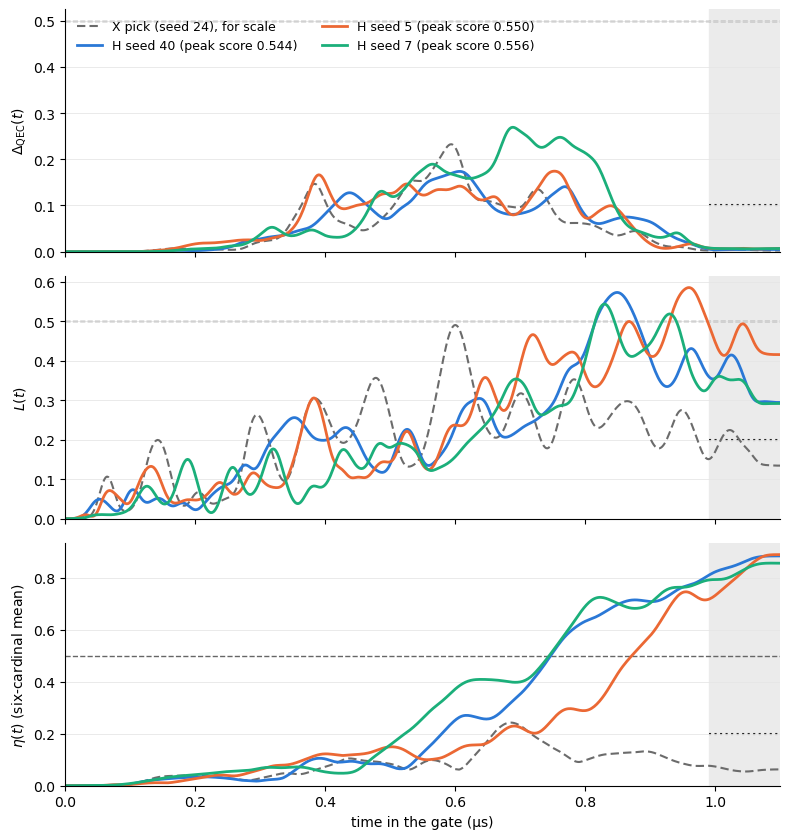

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8.5), sharex=True)
T_g = tr[f"{X_PICK}/final/t"][-1]
for ax, (key, label, peak, tail) in zip(axes, panels):
    ax.axvspan(S.TAIL_FRAC * T_g, T_g, color="0.92", zorder=0)
    ax.axhline(peak, color="0.4", lw=1, ls="--", zorder=1)
    ax.hlines(tail, S.TAIL_FRAC * T_g, T_g, color="0.15", lw=1.5, ls=":", zorder=1)
    ax.plot(tr[f"{X_PICK}/final/t"], tr[f"{X_PICK}/final/{key}"], color=CUR_COLOR, lw=1.5, ls=(0, (4, 2)),
            label="X pick (seed 24), for scale")
    for c, n in zip(COLORS, NEAR_H):
        ax.plot(trH[f"{n}/final/t"], trH[f"{n}/final/{key}"], color=c, lw=2,
                label=f"H seed {finH.loc[n].seed} (peak score {finH.loc[n].peak_score:.3f})")
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9", lw=0.6)
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
axes[-1].set_xlabel("time in the gate (μs)")
axes[-1].set_xlim(0, T_g)
fig.tight_layout()
fig.savefig("figures/est/fig_est_gate_seeds_H_nearmiss.png", dpi=150)
plt.show()

*Figure B1.* The three transparency metrics over the gate for the three H gates of Table B3 (solid), and the X pick of
§6 for scale (gray, dashed). The gray band is the tail, $t \ge 0.9\,T$. The dashed line is the peak bar (0.5), and
the dotted line in the band is the tail bar, which applies to the band's mean. The H gates follow the X pick's η
until about 0.55 μs, then η climbs to about 0.9 at the end.
*Symbols:* as in Figure 1.

## B.4 Follow-up: $C_{\rm err}$ kept in stage 2 (est_err2)

The H gates lose η in stage 2, where $C_{\rm err}$ is off. So each of the 21 H gates was rerun from its own
stage-1 pre-image with stage-2 weights $(w_1, w_2, w_3, w_4, w_{\rm err}) = (1, 0.1, 0, 1, 0.3)$: the same as
est_err's stage 2 but with $C_{\rm err}$ at its stage-1 weight. Stage 1 is unchanged, so this is variant
`est_err2`'s full run. Same rule, same ranking, 2000 iterations, one BLAS thread per run (about 52 min each).

In [19]:
pk1 = pickH.set_index("seed").loc[seeds2]
pk2 = pick2.set_index("seed").loc[seeds2]
f1 = finH.reset_index().set_index("seed").loc[seeds2]
rows = []
for col, lab, chk in [("F1", "F1", "F1_ok"), ("dqec_peak", "peak ΔQEC", "dqec_peak_ok"),
                      ("L_peak", "peak L", "L_peak_ok"), ("eta_peak", "peak η", "eta_peak_ok"),
                      ("dqec_tail", "tail ΔQEC", "dqec_tail_ok"), ("L_tail", "tail L", "L_tail_ok"),
                      ("eta_tail", "tail η", "eta_tail_ok"), ("peak_score", "peak score", None),
                      ("score", "score", None), ("max_active_fock", "max Fock", None)]:
    a, b = f1[col], fin2.loc[seeds2, col]
    rows.append({"metric": lab,
                 "est_err median [range]": f"{a.median():.3f} [{a.min():.3f}, {a.max():.3f}]",
                 "est_err2 median [range]": f"{b.median():.3f} [{b.min():.3f}, {b.max():.3f}]",
                 "change (median of pairs)": f"{(b - a).median():+.3f}",
                 "est_err2 lower": f"{int(((b - a) < 0).sum())}/{len(seeds2)}",
                 "fail est_err": "" if chk is None else int((~pk1[chk].astype(bool)).sum()),
                 "fail est_err2": "" if chk is None else int((~pk2[chk].astype(bool)).sum())})
display(pd.DataFrame(rows).set_index("metric").style
        .set_caption("Table B4. The 21 H gates without and with C_err in stage 2"))
print("est_err2 candidates:", int(pick2.candidate.sum()))

,est_err median [range],est_err2 median [range],change (median of pairs),est_err2 lower,fail est_err,fail est_err2
metric,,,,,,
F1,"0.998 [0.990, 0.999]","0.947 [0.935, 0.980]",-0.051,21/21,0,21
peak ΔQEC,"0.435 [0.174, 0.943]","0.869 [0.504, 2.460]",+0.485,0/21,7,21
peak L,"0.597 [0.531, 0.743]","0.680 [0.607, 0.747]",+0.073,4/21,21,21
peak η,"0.905 [0.716, 1.003]","0.441 [0.295, 0.653]",-0.468,21/21,21,4
tail ΔQEC,"0.007 [0.005, 0.083]","0.296 [0.077, 0.592]",+0.283,0/21,0,19
tail L,"0.425 [0.272, 0.697]","0.291 [0.221, 0.362]",-0.132,19/21,21,21
tail η,"0.857 [0.677, 0.979]","0.430 [0.215, 0.643]",-0.488,21/21,21,21
peak score,"0.624 [0.544, 0.820]","0.661 [0.542, 1.154]",+0.042,8/21,,
score,"0.215 [0.181, 0.285]","0.260 [0.198, 0.380]",+0.042,5/21,,


est_err2 candidates: 0


*Table B4.* Each row compares the 21 H gates of est_err with the same 21 seeds rerun as est_err2. "change" is the
median over seeds of (est_err2 − est_err); "est_err2 lower" counts the seeds where the est_err2 value is lower.
"fail" counts the seeds that fail that bar. No est_err2 run is a candidate either.
*Symbols:* as in Table 1. The truncation check passes for every run of both variants and is not shown.

## B.5 Conclusions at 1.1 μs

**No H gate passes the rule.** Neither the mirrored search (50 seeds) nor the follow-up with $C_{\rm err}$ in
stage 2 (21 reruns) gives a candidate, so there is no H pick.

- **How the 50 starts ended (est_err).**

  | | wave 1 (seeds 0-24) | wave 2 (seeds 25-49) | all | X (§6), all |
  |---|---|---|---|---|
  | parked | 15 | 13 | 28 | 22 |
  | trained against the wall | 1 (seed 9) | 0 | 1 | 1 (seed 9) |
  | made a gate | 9 | 12 | 21 | 27 |
  | candidates | 0 | 0 | 0 | 5 |

  Seed 9 hits the n_c 20 wall for both gates; its start pulse is the same.
- **The 21 H gates close well but are not transparent.** $F_1$ is 0.990–0.999 (median 0.998), so all pass the
  $F_1$ bar, but none reaches 0.999. All 21 fail the same four bars:
  - peak L 0.53–0.74 and tail L 0.27–0.70 (X medians: 0.51 and 0.19);
  - peak η 0.72–1.00 and tail η 0.68–0.98 (X medians: 0.24 and 0.10).
  - 7 also fail the ΔQEC peak; every ΔQEC tail passes (≤ 0.08).

  The closest misses by peak score are seeds 40 (0.544), 5 (0.550) and 7 (0.556) (Table B3), and each still fails
  those four bars.
- **The transparency is lost in stage 2, at the end of the gate.** At the end of stage 1 the same 21 runs have
  peak L 0.02–0.31 and η at $T$ 0.01–0.39, but $F_1$ only 0.24–0.83. Stage 2 has $C_{\rm err}$ off and $C_2$ at
  0.1. It finishes the gate, and η climbs over the last third of the gate to about 0.9 at $T$ (Figure 2). For X,
  stage 2 lowered η instead (median η tail 0.10).
- **Keeping $C_{\rm err}$ in stage 2 trades one failure for another (Table B4).**
  - η improves on every seed: peak −0.47, tail −0.49 (medians), and 17 of 21 now pass the η peak bar.
  - But $F_1$ falls by 0.05 to 0.936–0.980, so all 21 fail the $F_1$ bar.
  - ΔQEC rises on every seed (peak +0.48, and 19 tails now fail).
  - L stays over both bars (peak +0.07, tail −0.13).
  - The gates also reach higher Fock levels (median 18 against 13).
  - Every run stopped at the 2000-iteration limit, so $F_1$ may still have been rising.
- **In short:** at 1.1 μs on this chip, the H gate can be closed or kept transparent, but no seed and neither
  stage-2 cost does both. On the EST chip H was the *most* transparent gate (F_ET 0.818 against X's 0.730,
  `EST/README.md`), at 1.0 μs. Its χ is 3.3 times larger (3.66 against 1.12 MHz), so its gate lasted χT = 3.7
  cycles of χ, against 1.2 here. The short gate, measured in units of 1/χ, is the likely limit, not H itself.

The open-system score is computed only for candidates, so it was not run at 1.1 μs.

**What followed.** More seeds would not help, because the four failing bars fail on every seed. The gate was lengthened to 2 μs (§7.2–§7.8).
